# CSST102: Predicting Next-Day Air Quality in Laguna

**Student:** Manalo (Group ChunkyChucky) · **Project:** Development of an AI-Based Air Quality Forecasting and Mapping System for Residents and LGUs in Laguna

## Task
- **Problem type:** classification.
- **Question:** Can machine learning predict tomorrow's air quality level in Laguna from today's pollution readings, recent history, calendar factors, and weather?
- **Target variable (`target`):** tomorrow's air quality class, made from the OpenWeatherMap 1 to 5 level:
  - **0 = Good** (level 1), **1 = Fair** (level 2), **2 = Moderate or worse** (levels 3 to 5, merged because they are rare).
- **Data:** hourly air quality for Biñan, Cabuyao, and Calamba (Kaggle dataset based on OpenWeatherMap) and hourly weather (Open-Meteo), Nov 2023 to Oct 2026. The three towns have almost identical values, so they are treated as one Laguna series.
- **Models:** the main model is a **Random Forest classifier**. It is compared with a **Logistic Regression** and two baselines (majority class and "tomorrow = today"). All are built with scikit-learn. See the table below.
- **Metrics:** accuracy, macro-F1 (the average F1 over the three classes, so the rare class counts equally), and confusion matrices.

**How to run in Google Colab:** upload `laguna_hourly_clean.csv` and `weather_laguna.csv` when the first code cell asks, then click **Runtime > Run all**.

## Models used

| Model | Kind | How it works | Settings (chosen on the training data only) |
|---|---|---|---|
| Majority class | Baseline | Always predicts the most common class in the training data (`DummyClassifier`) | none |
| Persistence | Baseline (rule) | Predicts that tomorrow's class equals today's class | none |
| Logistic Regression (A) | Machine learning, second model | Weighs each input and turns the result into class probabilities (`StandardScaler` + `LogisticRegression`) | C = 0.1, no class weighting |
| **Random Forest (A)** | **Machine learning, main model** | 300 decision trees vote on tomorrow's class (`RandomForestClassifier`), using pollution and calendar features | depth 8, minimum leaf size 3, no class weighting |
| Random Forest (B) | Machine learning | Same model, with today's weather added | depth 5, minimum leaf size 10, no class weighting |


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CLASS_NAMES = ["Good", "Fair", "Moderate or worse"]

## 1. Load the data

In [2]:
# In Google Colab this asks you to upload the two files. On your own computer it reads them from the folder.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not (os.path.exists("laguna_hourly_clean.csv") and os.path.exists("weather_laguna.csv")):
    uploaded = files.upload()   # choose laguna_hourly_clean.csv and weather_laguna.csv

air = pd.read_csv("laguna_hourly_clean.csv", parse_dates=["datetime"])
weather = pd.read_csv("weather_laguna.csv", parse_dates=["datetime"])

# The clock values are Philippine local time; drop the time-zone label so both files match.
air["datetime"] = air["datetime"].dt.tz_localize(None)
weather["datetime"] = weather["datetime"].dt.tz_localize(None)

print("air quality rows:", len(air), "| weather rows:", len(weather))
print("air quality dates:", air["datetime"].min(), "to", air["datetime"].max())
air.head()

air quality rows: 18441 | weather rows: 25800
air quality dates: 2023-11-06 15:00:00 to 2026-10-21 22:00:00


,datetime,pm2_5,pm10,no2,o3,so2,co,no,nh3,aqi_level,year,month,hour,season
0,2023-11-06 15:00:00,3.95,6.73,9.77,58.65,14.42,307.08,0.61,2.44,1,2023,11,15,Rainy
1,2023-11-06 18:00:00,6.27,10.67,19.54,41.84,18.12,467.30,0.00,4.62,1,2023,11,18,Rainy
2,2023-11-07 00:00:00,5.90,11.54,15.42,42.56,18.84,370.50,0.00,4.02,1,2023,11,0,Rainy
3,2023-11-07 06:00:00,5.60,12.50,14.40,41.13,16.69,360.49,0.00,5.26,1,2023,11,6,Rainy
4,2023-11-07 12:00:00,4.63,8.37,10.37,75.10,12.76,357.15,0.38,3.36,2,2023,11,12,Rainy


### Quick data inspection
Check the data types, missing values, and duplicate timestamps before building anything.

In [3]:
print("Data types (air quality):")
print(air.dtypes.to_string())
print("\nMissing values per column (air quality):")
print(air.isna().sum().to_string())
print("\nDuplicate timestamps in the air quality data:", int(air.duplicated(subset="datetime").sum()))
print("\nMissing values per column (weather):")
print(weather.isna().sum().to_string())
print("Duplicate timestamps in the weather data:", int(weather.duplicated(subset="datetime").sum()))

Data types (air quality):
datetime     datetime64[us]
pm2_5               float64
pm10                float64
no2                 float64
o3                  float64
so2                 float64
co                  float64
no                  float64
nh3                 float64
aqi_level             int64
year                  int64
month                 int64
hour                  int64
season                  str

Missing values per column (air quality):
datetime     0
pm2_5        0
pm10         0
no2          1
o3           0
so2          1
co           0
no           0
nh3          0
aqi_level    0
year         0
month        0
hour         0
season       0

Duplicate timestamps in the air quality data: 0

Missing values per column (weather):
datetime       0
temperature    0
humidity       0
rain_mm        0
wind_kmh       0
Duplicate timestamps in the weather data: 0


## 2. Build a daily dataset
The target is about *tomorrow*, so each row is one **day**. Hourly values are averaged per day. Early data was recorded only every few hours and later data every hour, so averages (not maximums) are used to avoid favoring days with more readings.

In [4]:
air["date"] = air["datetime"].dt.floor("D")
pollutants = ["pm2_5", "pm10", "no2", "o3", "so2", "co", "no", "nh3"]

daily = air.groupby("date").agg({**{c: "mean" for c in pollutants}, "aqi_level": "mean"})
daily["aqi_today"] = daily["aqi_level"].round().astype(int).clip(1, 5)
daily = daily.drop(columns="aqi_level")

# Put every calendar day in the table (days with no readings become NaN)
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"))
daily.index.name = "date"

# Daily weather (from the full hourly weather file)
weather["date"] = weather["datetime"].dt.floor("D")
weather_daily = weather.groupby("date").agg(temp=("temperature", "mean"),
                                            humidity=("humidity", "mean"),
                                            rain=("rain_mm", "sum"),
                                            wind=("wind_kmh", "mean"))
daily = daily.join(weather_daily)

print("days:", len(daily), "| days with no air quality data:", int(daily["pm2_5"].isna().sum()))
daily.head()

days: 1081 | days with no air quality data: 14


,pm2_5,pm10,no2,o3,so2,co,no,nh3,aqi_today,temp,humidity,rain,wind
date,,,,,,,,,,,,,
2023-11-06,5.1100,8.7000,14.6550,50.2450,16.2700,387.1900,0.305,3.5300,1.0,28.054167,81.250000,1.7,18.633333
2023-11-07,5.0075,9.9550,14.0325,49.8000,16.2450,364.6600,0.095,3.9450,1.0,27.495833,82.166667,2.4,23.129167
2023-11-08,4.6700,8.9580,13.2620,31.0440,15.9740,337.7900,0.668,3.6360,1.0,27.179167,84.000000,3.4,21.145833
2023-11-09,4.1600,7.9675,12.4250,50.9625,16.8675,312.9250,0.250,3.0000,2.0,27.491667,83.458333,0.8,20.579167
2023-11-10,5.7475,11.2075,12.6800,57.9350,17.8850,332.1175,0.260,3.5475,2.0,27.675000,81.208333,0.1,18.508333


## 3. Target and features
- `class_today`: today's class (0, 1, or 2). `target` is the class of the **next** day.
- Lag and rolling features use only today and earlier days, so nothing from the future leaks in.
- **Feature set A (pollution + calendar):** today's pollutants, today's class, yesterday's class, PM2.5 for the last 1, 2, and 7 days, month, weekday, and rainy-season flag.
- **Feature set B:** A plus today's weather (temperature, humidity, rain, wind).

rows used: 1044
Good                41.5%
Fair                48.2%
Moderate or worse   10.3%


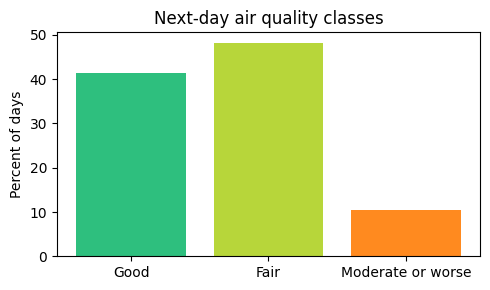

In [5]:
def to_class(level):
    # 1 -> 0 (Good), 2 -> 1 (Fair), 3 to 5 -> 2 (Moderate or worse)
    return np.where(level <= 1, 0, np.where(level == 2, 1, 2))

daily["class_today"] = np.where(daily["aqi_today"].isna(), np.nan, to_class(daily["aqi_today"].fillna(1)))
daily["target"] = daily["class_today"].shift(-1)        # tomorrow's class
daily["class_lag1"] = daily["class_today"].shift(1)     # yesterday's class
daily["pm25_lag1"] = daily["pm2_5"].shift(1)
daily["pm25_lag2"] = daily["pm2_5"].shift(2)
daily["pm25_roll7"] = daily["pm2_5"].rolling(7, min_periods=4).mean()
daily["month"] = daily.index.month
daily["dow"] = daily.index.dayofweek
daily["rainy_season"] = daily.index.month.isin(range(6, 12)).astype(int)   # Jun to Nov

FEATURES_A = pollutants + ["class_today", "class_lag1", "pm25_lag1", "pm25_lag2", "pm25_roll7",
                           "month", "dow", "rainy_season"]
FEATURES_B = FEATURES_A + ["temp", "humidity", "rain", "wind"]

# Both feature sets use the same rows, so their results can be compared fairly.
data = daily.dropna(subset=FEATURES_B + ["target"]).copy()
data["target"] = data["target"].astype(int)
data["class_today"] = data["class_today"].astype(int)

print("rows used:", len(data))
share = data["target"].value_counts(normalize=True).sort_index()
for k, v in share.items():
    print(f"{CLASS_NAMES[k]:<18} {v:6.1%}")

plt.figure(figsize=(5, 3))
plt.bar(CLASS_NAMES, [share.get(i, 0) * 100 for i in range(3)], color=["#2ebf7e", "#b7d63a", "#ff8a1f"])
plt.ylabel("Percent of days"); plt.title("Next-day air quality classes")
plt.tight_layout(); plt.show()

## 4. Chronological train/test split
Time series must not be shuffled. The **first 80% of days** train the models and the **last 20%** test them, so the test set is always in the future of the training set.

In [6]:
cut = int(len(data) * 0.8)
train, test = data.iloc[:cut], data.iloc[cut:]
y_train, y_test = train["target"], test["target"]

print(f"train: {len(train)} days, {train.index.min().date()} to {train.index.max().date()}")
print(f"test : {len(test)} days, {test.index.min().date()} to {test.index.max().date()}")
print("test class shares:", (y_test.value_counts(normalize=True).sort_index().round(3)).to_dict())

train: 835 days, 2023-11-09 to 2026-03-20
test : 209 days, 2026-03-21 to 2026-10-15
test class shares: {0: 0.478, 1: 0.44, 2: 0.081}


## 5. Baselines
1. **Majority class:** always predicts the most common class in the training data.
2. **Persistence:** predicts that tomorrow will be the same as today. This is a strong baseline for air quality, because it changes slowly from day to day.

In [7]:
results = []   # one row per model

def evaluate(name, pred_train, pred_test):
    results.append({
        "model": name,
        "train_accuracy": accuracy_score(y_train, pred_train),
        "test_accuracy": accuracy_score(y_test, pred_test),
        "test_macro_F1": f1_score(y_test, pred_test, average="macro"),
        "recall_moderate_or_worse": ((pred_test == 2) & (y_test == 2)).sum() / max((y_test == 2).sum(), 1),
    })

majority = DummyClassifier(strategy="most_frequent").fit(train[FEATURES_A], y_train)
evaluate("Baseline: majority class", majority.predict(train[FEATURES_A]), majority.predict(test[FEATURES_A]))

pers_train, pers_test = train["class_today"].values, test["class_today"].values
evaluate("Baseline: persistence (tomorrow = today)", pers_train, pers_test)

pd.DataFrame(results).round(3)

,model,train_accuracy,test_accuracy,test_macro_F1,recall_moderate_or_worse
0,Baseline: majority class,0.492,0.440,0.204,0.000
1,Baseline: persistence (tomorrow = today),0.740,0.742,0.666,0.471


## 6. Machine learning models
Settings are chosen with **time-aware cross-validation (`TimeSeriesSplit`) on the training data only**, scored by macro-F1. The test set is not used for tuning.

In [8]:
tscv = TimeSeriesSplit(n_splits=5)

# ---- Logistic Regression (feature set A) ----
lr_grid = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    {"logisticregression__C": [0.1, 1, 10],
     "logisticregression__class_weight": [None, "balanced"]},
    cv=tscv, scoring="f1_macro")
lr_grid.fit(train[FEATURES_A], y_train)
lr = lr_grid.best_estimator_
print("Logistic Regression best settings:", lr_grid.best_params_, "| CV macro-F1:", round(lr_grid.best_score_, 3))

# ---- Random Forest (feature set A: pollution + calendar) ----
rf_params = {"max_depth": [3, 5, 8], "min_samples_leaf": [3, 10], "class_weight": [None, "balanced"]}
rfA_grid = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                        rf_params, cv=tscv, scoring="f1_macro")
rfA_grid.fit(train[FEATURES_A], y_train)
rfA = rfA_grid.best_estimator_
print("Random Forest A best settings:", rfA_grid.best_params_, "| CV macro-F1:", round(rfA_grid.best_score_, 3))

# ---- Random Forest (feature set B: A + weather) ----
rfB_grid = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                        rf_params, cv=tscv, scoring="f1_macro")
rfB_grid.fit(train[FEATURES_B], y_train)
rfB = rfB_grid.best_estimator_
print("Random Forest B best settings:", rfB_grid.best_params_, "| CV macro-F1:", round(rfB_grid.best_score_, 3))

pred = {
    "Logistic Regression (A)": (lr.predict(train[FEATURES_A]), lr.predict(test[FEATURES_A])),
    "Random Forest (A: pollution + calendar)": (rfA.predict(train[FEATURES_A]), rfA.predict(test[FEATURES_A])),
    "Random Forest (B: + weather)": (rfB.predict(train[FEATURES_B]), rfB.predict(test[FEATURES_B])),
}
for name, (ptr, pte) in pred.items():
    evaluate(name, ptr, pte)

Logistic Regression best settings: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None} | CV macro-F1: 0.5


Random Forest A best settings: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 3} | CV macro-F1: 0.508


Random Forest B best settings: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 10} | CV macro-F1: 0.49


## 7. Results

In [9]:
results_df = pd.DataFrame(results).round(3)
results_df.to_csv("model_results.csv", index=False)
results_df

,model,train_accuracy,test_accuracy,test_macro_F1,recall_moderate_or_worse
0,Baseline: majority class,0.492,0.440,0.204,0.000
1,Baseline: persistence (tomorrow = today),0.740,0.742,0.666,0.471
2,Logistic Regression (A),0.780,0.718,0.494,0.000
3,Random Forest (A: pollution + calendar),0.893,0.713,0.493,0.000
4,Random Forest (B: + weather),0.807,0.684,0.472,0.000


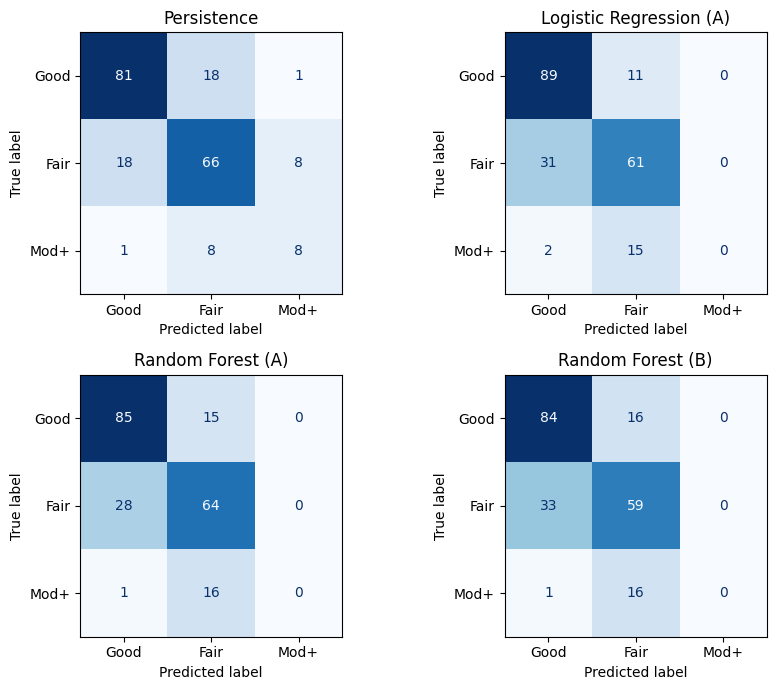

In [10]:
# Confusion matrices on the test set (rows = actual, columns = predicted)
models_to_plot = {
    "Persistence": pers_test,
    "Logistic Regression (A)": pred["Logistic Regression (A)"][1],
    "Random Forest (A)": pred["Random Forest (A: pollution + calendar)"][1],
    "Random Forest (B)": pred["Random Forest (B: + weather)"][1],
}
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (name, p) in zip(axes.ravel(), models_to_plot.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=["Good", "Fair", "Mod+"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [11]:
print("Random Forest (A) detailed report on the test set\n")
print(classification_report(y_test, pred["Random Forest (A: pollution + calendar)"][1],
                            labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

Random Forest (A) detailed report on the test set

                   precision    recall  f1-score   support

             Good       0.75      0.85      0.79       100
             Fair       0.67      0.70      0.68        92
Moderate or worse       0.00      0.00      0.00        17

         accuracy                           0.71       209
        macro avg       0.47      0.52      0.49       209
     weighted avg       0.65      0.71      0.68       209



## 8. Error analysis, overfitting, and what the model uses

                                   model  train_accuracy  test_accuracy
                Baseline: majority class           0.492          0.440
Baseline: persistence (tomorrow = today)           0.740          0.742
                 Logistic Regression (A)           0.780          0.718
 Random Forest (A: pollution + calendar)           0.893          0.713
            Random Forest (B: + weather)           0.807          0.684

Random Forest (A) mistakes: 60 of 209 test days; 98% of them were off by only one class.


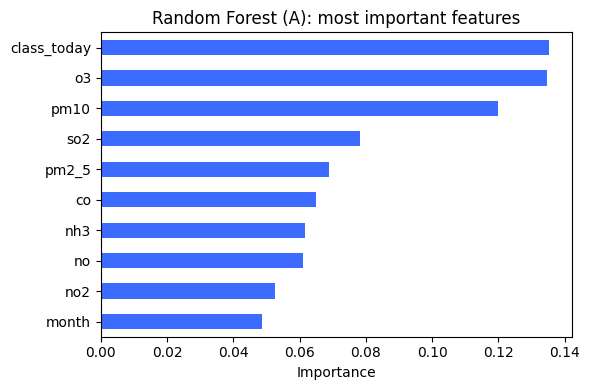

In [12]:
# Overfitting check: a large gap between train and test accuracy suggests overfitting
print(results_df[["model", "train_accuracy", "test_accuracy"]].to_string(index=False))

# How wrong are the Random Forest (A) mistakes?
p = pred["Random Forest (A: pollution + calendar)"][1]
errors = test.assign(actual=y_test, predicted=p)
errors = errors[errors["actual"] != errors["predicted"]]
off_by_one = (abs(errors["actual"] - errors["predicted"]) == 1).mean()
print(f"\nRandom Forest (A) mistakes: {len(errors)} of {len(test)} test days; {off_by_one:.0%} of them were off by only one class.")

# What the Random Forest (A) relies on most
imp = pd.Series(rfA.feature_importances_, index=FEATURES_A).sort_values().tail(10)
plt.figure(figsize=(6, 4)); imp.plot(kind="barh", color="#3b6cff")
plt.title("Random Forest (A): most important features"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()

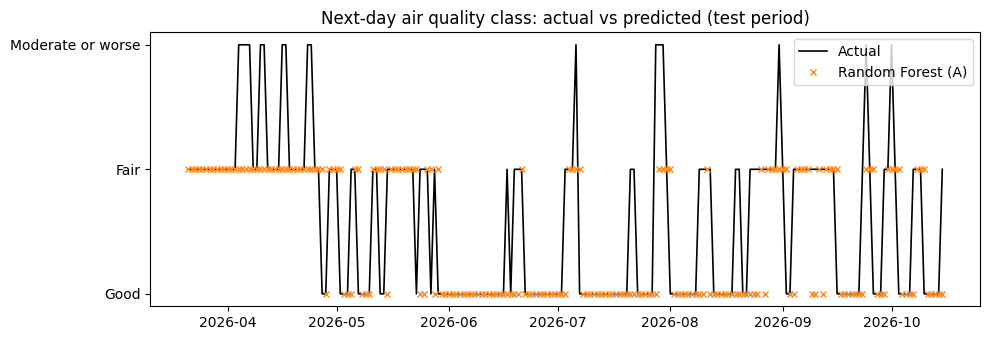

In [13]:
# Actual vs predicted over the test period
plt.figure(figsize=(10, 3.5))
plt.plot(test.index, y_test.values, color="black", label="Actual", linewidth=1.2)
plt.plot(test.index, p, "x", color="#ff8a1f", label="Random Forest (A)", markersize=4)
plt.yticks([0, 1, 2], CLASS_NAMES); plt.legend(loc="upper right")
plt.title("Next-day air quality class: actual vs predicted (test period)")
plt.tight_layout(); plt.show()

## 9. Save predictions and the forecast for the dashboard

In [14]:
# Predictions for every test day
predictions = pd.DataFrame({
    "date_of_prediction": test.index,
    "predicts_for": test.index + pd.Timedelta(days=1),
    "actual_class": y_test.values,
    "persistence": pers_test,
    "logistic_regression_A": pred["Logistic Regression (A)"][1],
    "random_forest_A": pred["Random Forest (A: pollution + calendar)"][1],
    "random_forest_B": pred["Random Forest (B: + weather)"][1],
})
predictions.to_csv("predictions_test.csv", index=False)

# Forecast for the day after the last complete day of data.
# The final model is refit on ALL available days, with the settings found above.
complete_days = air.groupby("date").size()
complete_days = complete_days[complete_days >= 20].index
usable = daily.loc[daily.index.isin(complete_days)].dropna(subset=FEATURES_A)
last_day = usable.index.max()

all_rows = daily.dropna(subset=FEATURES_A + ["target"]).copy()
all_rows["target"] = all_rows["target"].astype(int)
final_rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                  **rfA_grid.best_params_)
final_rf.fit(all_rows[FEATURES_A], all_rows["target"])

x_last = usable.loc[[last_day], FEATURES_A]
cls = int(final_rf.predict(x_last)[0])
proba = final_rf.predict_proba(x_last)[0]
proba = dict(zip(final_rf.classes_, proba))

rf_acc = results_df.loc[results_df["model"].str.startswith("Random Forest (A"), "test_accuracy"].iloc[0]
pers_acc = results_df.loc[results_df["model"].str.contains("persistence"), "test_accuracy"].iloc[0]

forecast = pd.DataFrame([{
    "date": (last_day + pd.Timedelta(days=1)).date(),
    "predicted_level": cls + 1,
    "predicted_label": CLASS_NAMES[cls],
    "prob_good": round(proba.get(0, 0), 3),
    "prob_fair": round(proba.get(1, 0), 3),
    "prob_moderate_or_worse": round(proba.get(2, 0), 3),
    "note": f"Random Forest. Test accuracy {rf_acc:.0%} (the simple 'same as today' rule scored {pers_acc:.0%}).",
}])
forecast.to_csv("forecast_next_day.csv", index=False)
print("Last complete day used:", last_day.date())
forecast

Last complete day used: 2026-10-21


,date,predicted_level,predicted_label,prob_good,prob_fair,prob_moderate_or_worse,note
0,2026-10-22,2,Fair,0.314,0.633,0.053,Random Forest. Test accuracy 71% (the simple '...


## 10. Discussion

*The numbers below are from my run of this notebook. If you run it again you should get the same or very close values.*

### What the results show
- The test set has 209 days (March 21 to October 15, 2026). Only 17 of them (8%) were "Moderate or worse."
- **Both machine learning models beat the majority-class baseline** (44% accuracy): Logistic Regression reached about 72% and the Random Forest (pollution + calendar features) about 71%.
- **Neither model beat the simple persistence baseline** ("tomorrow = today"), which scored about 74% accuracy and a macro-F1 of 0.67, compared with about 0.49 for both models. Air quality changes slowly from day to day, so yesterday's class is already a strong predictor.
- **Adding weather did not help.** The Random Forest with weather (B) scored lower (about 68%) than the one without it (A). This agrees with the CSST101 analysis, where weather had only very weak links with PM2.5.

### Errors
- The Random Forest (A) made 60 mistakes on 209 test days, and 98% of them were off by only one class (mostly Good vs Fair), so it was rarely badly wrong.
- **The rare "Moderate or worse" class was never predicted correctly by the machine learning models** (recall 0). The persistence baseline found about 47% of those days, because bad days tend to come in streaks. A tool that misses the days that matter most is a serious weakness.

### Overfitting
- The Random Forest (A) had a train accuracy of about 89% but a test accuracy of about 71%, which is a clear sign of **overfitting**. Logistic Regression had a smaller gap (about 78% train and 72% test). Tuning with time-aware cross-validation limited the problem but did not remove it.

### Data leakage
- The split is chronological (the first 80% of days to train, the last 20% to test), and nothing is shuffled.
- Lag and rolling features use only today and earlier days, and the target is the next day.
- Model settings were chosen only with cross-validation on the training data. The test set was used once for evaluation.
- One caution remains: feature set B uses *today's observed* weather. A real forecasting tool would have to use a weather forecast instead.

### Bias and limitations
- The air quality values are **modeled estimates** (OpenWeatherMap), not local sensor readings.
- Early data was recorded only every few hours, and later data every hour. The test period also falls mostly in the rainy season, so the training and test periods are not identical.
- Biñan, Cabuyao, and Calamba have almost identical values, so the model effectively predicts for one location.
- The classes are imbalanced, and levels 3 to 5 were merged into one class. The dataset covers only about three years.

### Conclusion and next steps
Machine learning can predict next-day air quality in Laguna with roughly 70% accuracy, but with these inputs it is **not better than assuming tomorrow will be like today**, and it misses the rare bad-air days. The dashboard forecast therefore shows the Random Forest result with a note about its accuracy, and should be treated as experimental. Possible improvements are more years of data, real sensor readings, forecast weather as an input, and a model designed for rare events.


## 11. References and data
- BwandoWando. (2026). *Philippine Cities Air Quality Index Data 2026* [Data set]. Kaggle. https://www.kaggle.com/datasets/bwandowando/philippine-cities-air-quality-index-data-2026 (hourly data from OpenWeatherMap).
- Zippenfenig, P. (2023). *Open-Meteo.com Weather API* [Computer software]. Zenodo. https://doi.org/10.5281/ZENODO.7970649
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Output files: `model_results.csv`, `predictions_test.csv`, `forecast_next_day.csv`.